In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


 # 🏷️ Milestone 3: Naive Bayes, KNN, SVM, Feature Selection & Dimensionality Reduction
 **Comment Category Prediction Challenge**

 **M2 Best Results:** Tuned LR → Accuracy 0.909, Macro F1 0.828 | Kaggle: 0.776

 **This notebook covers:**
 1. Milestone 3 Questions (all 10)
 2. Feature Selection & Dimensionality Reduction (TruncatedSVD, SelectKBest)
 3. **MultinomialNB** & **ComplementNB**
 4. **LinearSVC** (typically #1 for TF-IDF text)
 5. **PassiveAggressiveClassifier**
 6. **KNN** (with dimensionality reduction)
 7. **SVM** (SGD hinge as proxy for large data)
 8. Hyperparameter Tuning
 9. Model Comparison & Best Submission (targeting 0.90)

 ⚡ Uses Grandmaster-style precomputed TF-IDF pipeline.


## 1. Setup & Imports

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import string

from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV,
                                     cross_val_score)
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler,
                                   OneHotEncoder, LabelEncoder)
from sklearn.impute import SimpleImputer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_selection import SelectKBest, chi2

from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import (LogisticRegression, SGDClassifier,
                                  RidgeClassifier, PassiveAggressiveClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, make_scorer)

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12
sns.set_style("whitegrid")
sns.set_palette("viridis")

print("✅ All libraries imported successfully.")


✅ All libraries imported successfully.


## 2. Data Loading

In [4]:
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test  = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")


print(f"Train: {train.shape} | Test: {test.shape} | Sample: {sample.shape}")


Train: (198000, 15) | Test: (102000, 14) | Sample: (102000, 2)


## 3. Milestone 3 Questions

In [26]:
# ──────────────────────────────────────────────────────────
# 📌 M3 Q1: Split train with random_state=42, 80/20.
# If X_train shape (a,b) and X_val shape (c,d), what is a + c?
# ──────────────────────────────────────────────────────────

# Drop NaN comment first
train_clean = train.dropna(subset=["comment"]).copy()

X = train_clean.drop(columns=["label"])
y = train_clean["label"]

X_train_q, X_val_q, y_train_q, y_val_q = train_test_split(
    X, y, test_size=0.2, random_state=42
)

a, b = X_train_q.shape
c, d = X_val_q.shape

print(f"🔹 X_train shape: ({a}, {b})")
print(f"🔹 X_val shape:   ({c}, {d})")
print(f"\n→ ANSWER: a + c = {a} + {c} = {a + c}")


🔹 X_train shape: (158399, 14)
🔹 X_val shape:   (39600, 14)

→ ANSWER: a + c = 158399 + 39600 = 197999


In [27]:
# ──────────────────────────────────────────────────────────
# 📌 M3 Q2: Convert created_date to datetime, extract day/month/year
# for X_train and X_val. Most frequently occurring month in X_train?
# ──────────────────────────────────────────────────────────

X_train_q["created_date"] = pd.to_datetime(X_train_q["created_date"], errors="coerce")
X_val_q["created_date"]   = pd.to_datetime(X_val_q["created_date"], errors="coerce")

X_train_q["day"]   = X_train_q["created_date"].dt.day
X_train_q["month"] = X_train_q["created_date"].dt.month
X_train_q["year"]  = X_train_q["created_date"].dt.year

X_val_q["day"]   = X_val_q["created_date"].dt.day
X_val_q["month"] = X_val_q["created_date"].dt.month
X_val_q["year"]  = X_val_q["created_date"].dt.year

month_counts = X_train_q["month"].value_counts()
most_freq_month = month_counts.index[0]
month_names = {1:"January", 2:"February", 3:"March", 4:"April", 5:"May",
               6:"June", 7:"July", 8:"August", 9:"September", 10:"October",
               11:"November", 12:"December"}

print(f"🔹 Month value counts in X_train:")
print(month_counts)
print(f"\n→ ANSWER: Most frequent month = {most_freq_month} ({month_names.get(most_freq_month, 'Unknown')})")


🔹 Month value counts in X_train:
month
5     18824
3     17045
4     16068
2     15662
1     15218
12    12252
8     11346
10    11158
11    10795
6     10658
9      9884
7      9489
Name: count, dtype: int64

→ ANSWER: Most frequent month = 5 (May)


In [28]:
# ──────────────────────────────────────────────────────────
# 📌 M3 Q3: Impute null values of categorical features with 'none'.
# One-hot encode ONLY religion, gender, race with handle_unknown='ignore'.
# Shape of X_train after imputing → what is b?
# Also transform X_val.
# ──────────────────────────────────────────────────────────

# Identify categorical columns
cat_cols = X_train_q.select_dtypes(include=["object"]).columns.tolist()
# Remove 'comment' from cat_cols for imputation (we handle text separately)
cat_cols_to_impute = [c for c in cat_cols if c != "comment"]
print(f"Categorical columns to impute: {cat_cols_to_impute}")

# Impute categorical nulls with 'none'
for col in cat_cols_to_impute:
    X_train_q[col] = X_train_q[col].fillna("none")
    X_val_q[col]   = X_val_q[col].fillna("none")

print(f"\n🔹 X_train shape after imputing: {X_train_q.shape}")
print(f"→ ANSWER (shape after imputing): b = {X_train_q.shape[1]}")

# One-hot encode religion, gender, race
ohe_cols = ["religion", "gender", "race"]
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe.fit(X_train_q[ohe_cols])

X_train_ohe = pd.DataFrame(
    ohe.transform(X_train_q[ohe_cols]),
    columns=ohe.get_feature_names_out(ohe_cols),
    index=X_train_q.index
)
X_val_ohe = pd.DataFrame(
    ohe.transform(X_val_q[ohe_cols]),
    columns=ohe.get_feature_names_out(ohe_cols),
    index=X_val_q.index
)

# Drop original columns and add encoded
X_train_q = X_train_q.drop(columns=ohe_cols).join(X_train_ohe)
X_val_q   = X_val_q.drop(columns=ohe_cols).join(X_val_ohe)

print(f"\n🔹 X_train shape after OHE: {X_train_q.shape}")
print(f"🔹 X_val shape after OHE:   {X_val_q.shape}")
print(f"🔹 OHE feature names: {ohe.get_feature_names_out(ohe_cols).tolist()}")


Categorical columns to impute: ['race', 'religion', 'gender']

🔹 X_train shape after imputing: (158399, 17)
→ ANSWER (shape after imputing): b = 17

🔹 X_train shape after OHE: (158399, 33)
🔹 X_val shape after OHE:   (39600, 33)
🔹 OHE feature names: ['religion_atheist', 'religion_buddhist', 'religion_christian', 'religion_hindu', 'religion_jewish', 'religion_muslim', 'religion_none', 'religion_other', 'gender_female', 'gender_male', 'gender_none', 'gender_other', 'gender_transgender', 'race_asian', 'race_black', 'race_latino', 'race_none', 'race_other', 'race_white']


In [29]:
# ──────────────────────────────────────────────────────────
# 📌 M3 Q4: Apply CountVectorizer to comment column of X_train and X_val.
# Sum of counts for document at index 1 (second row) of transformed X_train?
# ──────────────────────────────────────────────────────────

cv = CountVectorizer()
X_train_cv = cv.fit_transform(X_train_q["comment"].astype(str))
X_val_cv   = cv.transform(X_val_q["comment"].astype(str))

# Index 1 = second row
doc_1_sum = X_train_cv[1].sum()
print(f"🔹 CountVectorizer X_train shape: {X_train_cv.shape}")
print(f"🔹 Sum of counts at index 1 (second row): {doc_1_sum}")
print(f"\n→ ANSWER: Sum of counts for document at index 1 = {doc_1_sum}")


🔹 CountVectorizer X_train shape: (158399, 149674)
🔹 Sum of counts at index 1 (second row): 41

→ ANSWER: Sum of counts for document at index 1 = 41


In [30]:
# ──────────────────────────────────────────────────────────
# 📌 M3 Q5: Convert disability to int (True→1, False→0).
# Sum of all disability values in X_train and X_val?
# ──────────────────────────────────────────────────────────

X_train_q["disability"] = X_train_q["disability"].astype(int)
X_val_q["disability"]   = X_val_q["disability"].astype(int)

disability_sum_train = X_train_q["disability"].sum()
disability_sum_val   = X_val_q["disability"].sum()
total_disability = disability_sum_train + disability_sum_val

print(f"🔹 Disability sum in X_train: {disability_sum_train}")
print(f"🔹 Disability sum in X_val:   {disability_sum_val}")
print(f"\n→ ANSWER: Total disability sum = {total_disability}")


🔹 Disability sum in X_train: 2184
🔹 Disability sum in X_val:   559

→ ANSWER: Total disability sum = 2743


In [31]:
# ──────────────────────────────────────────────────────────
# 📌 M3 Q6: Scale numeric features using StandardScaler.
# Number of features seen during fit for X_train?
# Drop all datetime columns first.
# ──────────────────────────────────────────────────────────

# Drop datetime columns
datetime_cols = X_train_q.select_dtypes(include=["datetime64"]).columns.tolist()
print(f"Datetime columns to drop: {datetime_cols}")

X_train_q6 = X_train_q.drop(columns=datetime_cols, errors="ignore")
X_val_q6   = X_val_q.drop(columns=datetime_cols, errors="ignore")

# Also drop non-numeric columns (comment, etc.)
non_numeric = X_train_q6.select_dtypes(include=["object"]).columns.tolist()
print(f"Non-numeric columns (excluded from scaling): {non_numeric}")

numeric_cols_q6 = X_train_q6.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numeric columns for scaling: {numeric_cols_q6}")

scaler_q6 = StandardScaler()
scaler_q6.fit(X_train_q6[numeric_cols_q6])

n_features_seen = scaler_q6.n_features_in_
print(f"\n🔹 Number of features seen during fit: {n_features_seen}")
print(f"\n→ ANSWER: Features seen during StandardScaler fit = {n_features_seen}")


Datetime columns to drop: []
Non-numeric columns (excluded from scaling): ['comment']
Numeric columns for scaling: ['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'disability', 'day', 'month', 'year', 'religion_atheist', 'religion_buddhist', 'religion_christian', 'religion_hindu', 'religion_jewish', 'religion_muslim', 'religion_none', 'religion_other', 'gender_female', 'gender_male', 'gender_none', 'gender_other', 'gender_transgender', 'race_asian', 'race_black', 'race_latino', 'race_none', 'race_other', 'race_white']

🔹 Number of features seen during fit: 31

→ ANSWER: Features seen during StandardScaler fit = 31


In [32]:
# ──────────────────────────────────────────────────────────
# 📌 M3 Q7 & Q8: Full preprocessing → MultinomialNB → Macro F1 on
# train AND validation.
#
# Steps:
# 1. Split 80/20
# 2. SimpleImputer fit on X_train, transform both
# 3. Ensure no negative values (abs)
# 4. Convert created_date → day, month, year; drop created_date
# 5. TfidfVectorizer(stop_words='english') on comment
# 6. OneHotEncoder(handle_unknown='ignore') on categorical features
# 7. Train MultinomialNB
# 8. Report macro F1 on train and val
# ──────────────────────────────────────────────────────────

# Fresh reload for clean preprocessing
train_q7 = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")

train_q7 = train_q7.dropna(subset=["comment"])

X_q7 = train_q7.drop(columns=["label"])
y_q7 = train_q7["label"]

X_train_q7, X_val_q7, y_train_q7, y_val_q7 = train_test_split(
    X_q7, y_q7, test_size=0.2, random_state=42
)

# Step 2: SimpleImputer
# Separate numeric and non-numeric
num_cols_q7 = X_train_q7.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_q7 = X_train_q7.select_dtypes(include=["object", "bool"]).columns.tolist()
cat_cols_q7_no_comment = [c for c in cat_cols_q7 if c != "comment"]

# Impute numeric with mean
num_imputer = SimpleImputer(strategy="mean")
X_train_q7[num_cols_q7] = num_imputer.fit_transform(X_train_q7[num_cols_q7])
X_val_q7[num_cols_q7]   = num_imputer.transform(X_val_q7[num_cols_q7])

# Impute categorical with most_frequent
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_q7[cat_cols_q7_no_comment] = cat_imputer.fit_transform(X_train_q7[cat_cols_q7_no_comment])
X_val_q7[cat_cols_q7_no_comment]   = cat_imputer.transform(X_val_q7[cat_cols_q7_no_comment])

# Step 3: Ensure no negative values
for col in num_cols_q7:
    X_train_q7[col] = X_train_q7[col].abs()
    X_val_q7[col]   = X_val_q7[col].abs()

# Step 4: created_date → day, month, year
X_train_q7["created_date"] = pd.to_datetime(X_train_q7["created_date"], errors="coerce")
X_val_q7["created_date"]   = pd.to_datetime(X_val_q7["created_date"], errors="coerce")

for df in [X_train_q7, X_val_q7]:
    df["day"]   = df["created_date"].dt.day
    df["month"] = df["created_date"].dt.month
    df["year"]  = df["created_date"].dt.year

X_train_q7 = X_train_q7.drop(columns=["created_date"])
X_val_q7   = X_val_q7.drop(columns=["created_date"])

# Step 5: TF-IDF on comment
tfidf_q7 = TfidfVectorizer(stop_words="english")
X_train_text_q7 = tfidf_q7.fit_transform(X_train_q7["comment"].astype(str))
X_val_text_q7   = tfidf_q7.transform(X_val_q7["comment"].astype(str))

# Step 6: OneHotEncoder on categorical features
cat_features_q7 = [c for c in X_train_q7.columns
                    if X_train_q7[c].dtype == "object" and c != "comment"]
# Also include boolean columns
bool_cols_q7 = X_train_q7.select_dtypes(include=["bool"]).columns.tolist()
# Convert bool to string for OHE
for col in bool_cols_q7:
    X_train_q7[col] = X_train_q7[col].astype(str)
    X_val_q7[col]   = X_val_q7[col].astype(str)
cat_features_q7 = cat_features_q7 + bool_cols_q7

print(f"Categorical features for OHE: {cat_features_q7}")

ohe_q7 = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
X_train_cat_q7 = ohe_q7.fit_transform(X_train_q7[cat_features_q7])
X_val_cat_q7   = ohe_q7.transform(X_val_q7[cat_features_q7])

# Get remaining numeric columns (drop comment and cat features)
num_cols_final_q7 = [c for c in X_train_q7.columns
                     if c not in cat_features_q7 and c != "comment"
                     and X_train_q7[c].dtype in [np.int64, np.float64, np.int32, np.float32]]

print(f"Numeric features: {num_cols_final_q7}")

X_train_num_q7 = csr_matrix(X_train_q7[num_cols_final_q7].values)
X_val_num_q7   = csr_matrix(X_val_q7[num_cols_final_q7].values)

# Combine all
X_train_final_q7 = hstack([X_train_text_q7, X_train_num_q7, X_train_cat_q7])
X_val_final_q7   = hstack([X_val_text_q7, X_val_num_q7, X_val_cat_q7])

print(f"\nCombined train matrix: {X_train_final_q7.shape}")
print(f"Combined val matrix:   {X_val_final_q7.shape}")

# Step 7: Train MultinomialNB
mnb_q7 = MultinomialNB()
mnb_q7.fit(X_train_final_q7, y_train_q7)

# Step 8: Macro F1
y_train_pred_q7 = mnb_q7.predict(X_train_final_q7)
y_val_pred_q7   = mnb_q7.predict(X_val_final_q7)

f1_train_q7 = f1_score(y_train_q7, y_train_pred_q7, average="macro")
f1_val_q7   = f1_score(y_val_q7, y_val_pred_q7, average="macro")

print(f"\n🔹 MultinomialNB - Macro F1 on TRAIN: {f1_train_q7:.4f}")
print(f"🔹 MultinomialNB - Macro F1 on VAL:   {f1_val_q7:.4f}")
print(f"\n→ ANSWER Q7: Macro F1 on train = {f1_train_q7:.4f}")
print(f"→ ANSWER Q8: Macro F1 on val   = {f1_val_q7:.4f}")


Categorical features for OHE: ['race', 'religion', 'gender', 'disability']
Numeric features: ['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'day', 'month', 'year']

Combined train matrix: (158399, 149394)
Combined val matrix:   (39600, 149394)

🔹 MultinomialNB - Macro F1 on TRAIN: 0.4815
🔹 MultinomialNB - Macro F1 on VAL:   0.4602

→ ANSWER Q7: Macro F1 on train = 0.4815
→ ANSWER Q8: Macro F1 on val   = 0.4602


In [33]:
# ──────────────────────────────────────────────────────────
# 📌 M3 Q9 & Q10: Same as Q7-Q8 but add is_weekend feature.
# is_weekend = 1 for Saturday/Sunday, 0 otherwise.
# ──────────────────────────────────────────────────────────

# Fresh reload
train_q9 = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")

train_q9 = train_q9.dropna(subset=["comment"])

X_q9 = train_q9.drop(columns=["label"])
y_q9 = train_q9["label"]

X_train_q9, X_val_q9, y_train_q9, y_val_q9 = train_test_split(
    X_q9, y_q9, test_size=0.2, random_state=42
)

# Impute
num_cols_q9 = X_train_q9.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_q9 = X_train_q9.select_dtypes(include=["object", "bool"]).columns.tolist()
cat_cols_q9_nc = [c for c in cat_cols_q9 if c != "comment"]

num_imp_q9 = SimpleImputer(strategy="mean")
X_train_q9[num_cols_q9] = num_imp_q9.fit_transform(X_train_q9[num_cols_q9])
X_val_q9[num_cols_q9]   = num_imp_q9.transform(X_val_q9[num_cols_q9])

cat_imp_q9 = SimpleImputer(strategy="most_frequent")
X_train_q9[cat_cols_q9_nc] = cat_imp_q9.fit_transform(X_train_q9[cat_cols_q9_nc])
X_val_q9[cat_cols_q9_nc]   = cat_imp_q9.transform(X_val_q9[cat_cols_q9_nc])

# Ensure no negative values
for col in num_cols_q9:
    X_train_q9[col] = X_train_q9[col].abs()
    X_val_q9[col]   = X_val_q9[col].abs()

# Datetime engineering
X_train_q9["created_date"] = pd.to_datetime(X_train_q9["created_date"], errors="coerce")
X_val_q9["created_date"]   = pd.to_datetime(X_val_q9["created_date"], errors="coerce")

for df in [X_train_q9, X_val_q9]:
    df["day"]   = df["created_date"].dt.day
    df["month"] = df["created_date"].dt.month
    df["year"]  = df["created_date"].dt.year
    # NEW: is_weekend (Saturday=5, Sunday=6)
    df["is_weekend"] = (df["created_date"].dt.dayofweek >= 5).astype(int)

X_train_q9 = X_train_q9.drop(columns=["created_date"])
X_val_q9   = X_val_q9.drop(columns=["created_date"])

# TF-IDF
tfidf_q9 = TfidfVectorizer(stop_words="english")
X_train_text_q9 = tfidf_q9.fit_transform(X_train_q9["comment"].astype(str))
X_val_text_q9   = tfidf_q9.transform(X_val_q9["comment"].astype(str))

# OHE on categorical features INCLUDING is_weekend
cat_features_q9 = [c for c in X_train_q9.columns
                    if X_train_q9[c].dtype == "object" and c != "comment"]
bool_cols_q9 = X_train_q9.select_dtypes(include=["bool"]).columns.tolist()
for col in bool_cols_q9:
    X_train_q9[col] = X_train_q9[col].astype(str)
    X_val_q9[col]   = X_val_q9[col].astype(str)
cat_features_q9 = cat_features_q9 + bool_cols_q9

# Add is_weekend as categorical for OHE
X_train_q9["is_weekend"] = X_train_q9["is_weekend"].astype(str)
X_val_q9["is_weekend"]   = X_val_q9["is_weekend"].astype(str)
if "is_weekend" not in cat_features_q9:
    cat_features_q9.append("is_weekend")

print(f"Categorical features for OHE (with is_weekend): {cat_features_q9}")

ohe_q9 = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
X_train_cat_q9 = ohe_q9.fit_transform(X_train_q9[cat_features_q9])
X_val_cat_q9   = ohe_q9.transform(X_val_q9[cat_features_q9])

num_cols_final_q9 = [c for c in X_train_q9.columns
                     if c not in cat_features_q9 and c != "comment"
                     and X_train_q9[c].dtype in [np.int64, np.float64, np.int32, np.float32]]

X_train_num_q9 = csr_matrix(X_train_q9[num_cols_final_q9].values)
X_val_num_q9   = csr_matrix(X_val_q9[num_cols_final_q9].values)

X_train_final_q9 = hstack([X_train_text_q9, X_train_num_q9, X_train_cat_q9])
X_val_final_q9   = hstack([X_val_text_q9, X_val_num_q9, X_val_cat_q9])

print(f"Combined train: {X_train_final_q9.shape} | Combined val: {X_val_final_q9.shape}")

# Train MultinomialNB
mnb_q9 = MultinomialNB()
mnb_q9.fit(X_train_final_q9, y_train_q9)

y_train_pred_q9 = mnb_q9.predict(X_train_final_q9)
y_val_pred_q9   = mnb_q9.predict(X_val_final_q9)

f1_train_q9 = f1_score(y_train_q9, y_train_pred_q9, average="macro")
f1_val_q9   = f1_score(y_val_q9, y_val_pred_q9, average="macro")

print(f"\n🔹 MultinomialNB (with is_weekend) - Macro F1 on TRAIN: {f1_train_q9:.4f}")
print(f"🔹 MultinomialNB (with is_weekend) - Macro F1 on VAL:   {f1_val_q9:.4f}")
print(f"\n→ ANSWER Q9:  Macro F1 on train = {f1_train_q9:.4f}")
print(f"→ ANSWER Q10: Macro F1 on val   = {f1_val_q9:.4f}")



Categorical features for OHE (with is_weekend): ['race', 'religion', 'gender', 'disability', 'is_weekend']
Combined train: (158399, 149396) | Combined val: (39600, 149396)

🔹 MultinomialNB (with is_weekend) - Macro F1 on TRAIN: 0.4813
🔹 MultinomialNB (with is_weekend) - Macro F1 on VAL:   0.4602

→ ANSWER Q9:  Macro F1 on train = 0.4813
→ ANSWER Q10: Macro F1 on val   = 0.4602


## 4. Feature Engineering (for Competition Models)
# Now we switch to the optimized Grandmaster pipeline for the actual competition models.


In [5]:
# Fresh load for competition modeling
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test  = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")


train = train.dropna(subset=["comment"])

In [6]:



# ---- Feature engineering ----
for df in [train, test]:
    df["comment"] = df["comment"].fillna("")
    df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")
    df["hour"] = df["created_date"].dt.hour
    df["day_of_week"] = df["created_date"].dt.dayofweek
    df["month"] = df["created_date"].dt.month
    df["comment_length"] = df["comment"].astype(str).str.len()
    df["word_count"] = df["comment"].astype(str).str.split().str.len().fillna(0).astype(int)
    df["avg_word_length"] = df["comment_length"] / (df["word_count"] + 1)
    df["total_votes"] = df["upvote"] + df["downvote"]
    df["vote_diff"] = df["upvote"] - df["downvote"]
    df["vote_ratio"] = df["upvote"] / (df["downvote"] + 1)
    df["total_emoticons"] = df["emoticon_1"] + df["emoticon_2"] + df["emoticon_3"]
    for col in ["race", "religion", "gender"]:
        df[col] = df[col].fillna("missing")
    df["has_detection"] = (df[["race","religion","gender"]].ne("missing").any(axis=1)).astype(int)

print(f"✅ Feature engineering done. Train: {train.shape} | Test: {test.shape}")


✅ Feature engineering done. Train: (197999, 26) | Test: (102000, 25)


## 5. ⚡ Grandmaster Pipeline — Precompute Features


In [7]:
# ════════════════════════════════════════════════════════════
# STEP 1: TF-IDF (computed ONCE)
# ════════════════════════════════════════════════════════════
print("⏳ Computing TF-IDF...")
t0 = time.time()

tfidf = TfidfVectorizer(
    max_features=15000,        # Increased from 10K for better score
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3, max_df=0.9,
    sublinear_tf=True
)

X_text_train = tfidf.fit_transform(train["comment"].astype(str))
X_text_test  = tfidf.transform(test["comment"].astype(str))
print(f"✅ TF-IDF done in {time.time()-t0:.1f}s → {X_text_train.shape[1]} features")


⏳ Computing TF-IDF...
✅ TF-IDF done in 34.2s → 15000 features


In [10]:
# ════════════════════════════════════════════════════════════
# STEP 2: Character N-gram TF-IDF (extra signal for better score)
# ════════════════════════════════════════════════════════════
print("⏳ Computing char n-gram TF-IDF...")
t0 = time.time()

tfidf_char = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=10000,
    min_df=3, max_df=0.9,
    sublinear_tf=True
)

X_char_train = tfidf_char.fit_transform(train["comment"].astype(str))
X_char_test  = tfidf_char.transform(test["comment"].astype(str))
print(f"✅ Char TF-IDF done in {time.time()-t0:.1f}s → {X_char_train.shape[1]} features")


⏳ Computing char n-gram TF-IDF...
✅ Char TF-IDF done in 122.5s → 10000 features


In [13]:
# ════════════════════════════════════════════════════════════
# STEP 3: Numeric & Binary features
# ════════════════════════════════════════════════════════════
numeric_features = [
    "upvote", "downvote", "if_1", "if_2",
    "comment_length", "word_count", "avg_word_length",
    "total_votes", "vote_diff", "vote_ratio",
    "total_emoticons", "hour", "day_of_week", "month"
]
binary_features = [
    "emoticon_1", "emoticon_2", "emoticon_3",
    "disability", "has_detection"
]

X_num_train = train[numeric_features].values.copy()
X_bin_train = train[binary_features].values.astype(float)
X_num_test  = test[numeric_features].values.copy()
X_bin_test  = test[binary_features].values.astype(float)

y = train["label"].values

# Log transform skewed features
skewed_cols = ["upvote", "downvote", "if_1", "if_2",
               "total_votes", "vote_ratio", "comment_length", "word_count"]
skewed_idx = [numeric_features.index(c) for c in skewed_cols]

for idx in skewed_idx:
    X_num_train[:, idx] = np.log1p(np.clip(X_num_train[:, idx], 0, None))
    X_num_test[:, idx]  = np.log1p(np.clip(X_num_test[:, idx], 0, None))

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)
X_num_scaled_test  = scaler.transform(X_num_test)


In [14]:
# ════════════════════════════════════════════════════════════
# STEP 4: Combine all features
# ════════════════════════════════════════════════════════════

# Version A: Word TF-IDF only (for NB models that need non-negative input)
X_all_nonneg = hstack([X_text_train, X_char_train, csr_matrix(X_bin_train)])

# Version B: Full features with scaling (for SVM, LR, etc.)
X_all = hstack([X_text_train, X_char_train,
                csr_matrix(X_num_scaled_train), csr_matrix(X_bin_train)])
X_test_all = hstack([X_text_test, X_char_test,
                     csr_matrix(X_num_scaled_test), csr_matrix(X_bin_test)])

# Version C: Non-negative full (for NB with numerics — abs scale)
X_num_mm_train = MinMaxScaler().fit_transform(X_num_train)
X_num_mm_test  = MinMaxScaler().fit(X_num_train).transform(X_num_test)
X_all_nonneg_full = hstack([X_text_train, X_char_train,
                            csr_matrix(X_num_mm_train), csr_matrix(X_bin_train)])
X_test_nonneg_full = hstack([X_text_test, X_char_test,
                             csr_matrix(X_num_mm_test), csr_matrix(X_bin_test)])

print(f"✅ Feature matrices ready:")
print(f"   Full (scaled):     {X_all.shape}")
print(f"   Non-neg (NB):      {X_all_nonneg.shape}")
print(f"   Non-neg full (NB): {X_all_nonneg_full.shape}")


✅ Feature matrices ready:
   Full (scaled):     (197999, 25019)
   Non-neg (NB):      (197999, 25005)
   Non-neg full (NB): (197999, 25019)


In [15]:
# ════════════════════════════════════════════════════════════
# STEP 5: Train-Validation Split
# ════════════════════════════════════════════════════════════
indices = np.arange(len(y))
idx_train, idx_val = train_test_split(indices, test_size=0.2, stratify=y, random_state=42)

X_tr, X_vl = X_all[idx_train], X_all[idx_val]
X_tr_nn, X_vl_nn = X_all_nonneg_full[idx_train], X_all_nonneg_full[idx_val]
y_tr, y_vl = y[idx_train], y[idx_val]

print(f"✅ Split: Train={len(y_tr):,} | Val={len(y_vl):,}")


✅ Split: Train=158,399 | Val=39,600


## 6. Evaluation Helper

In [16]:
all_results = []

def evaluate_model(name, y_true, y_pred, detailed=True):
    acc = accuracy_score(y_true, y_pred)
    f1_mac = f1_score(y_true, y_pred, average="macro")
    f1_wt  = f1_score(y_true, y_pred, average="weighted")
    print(f"\n{'='*65}")
    print(f"  {name}")
    print(f"{'='*65}")
    print(f"  Accuracy:     {acc:.4f}")
    print(f"  Macro F1:     {f1_mac:.4f}")
    print(f"  Weighted F1:  {f1_wt:.4f}")
    if detailed:
        print(f"\n{classification_report(y_true, y_pred, digits=4)}")
    result = {"name": name, "accuracy": acc, "macro_f1": f1_mac, "weighted_f1": f1_wt}
    all_results.append(result)
    return result

f1_macro_scorer = make_scorer(f1_score, average="macro")
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)


## 7. Model 1: MultinomialNB

In [17]:
# ──────────────────────────────────────────────────────────
# DEFAULT MultinomialNB — COMMENTED OUT (already ran in first pass)
# LESSON LEARNED: Default alpha=1.0 gave Macro F1 ~0.64, Accuracy ~0.74
# Tuned version below finds optimal alpha, so running default first is redundant.
# ──────────────────────────────────────────────────────────
# print("⏳ MultinomialNB...")
# t0 = time.time()
# mnb = MultinomialNB(alpha=1.0)
# mnb.fit(X_tr_nn, y_tr)
# evaluate_model("MultinomialNB (default)", y_vl, mnb.predict(X_vl_nn))
# print(f"  ⏱️ {time.time()-t0:.1f}s")
# RESULT FROM FIRST RUN:
#   Accuracy: 0.7396 | Macro F1: 0.6424 | Weighted F1: 0.7382
#   Label 3 F1: very low (~0.35) — MultinomialNB struggles with minority classes


In [18]:
# Tuning alpha
print("⏳ GridSearchCV for MultinomialNB...")
t0 = time.time()
grid_mnb = GridSearchCV(
    MultinomialNB(),
    {"alpha": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]},
    cv=cv, scoring=f1_macro_scorer, n_jobs=-1, verbose=1, refit=True
)
grid_mnb.fit(X_all_nonneg_full, y)
print(f"✅ Done in {time.time()-t0:.1f}s | Best alpha={grid_mnb.best_params_} | CV F1={grid_mnb.best_score_:.4f}")

evaluate_model("Tuned MultinomialNB", y_vl, grid_mnb.predict(X_all_nonneg_full[idx_val]))


⏳ GridSearchCV for MultinomialNB...
Fitting 3 folds for each of 7 candidates, totalling 21 fits
✅ Done in 11.9s | Best alpha={'alpha': 0.1} | CV F1=0.6373

  Tuned MultinomialNB
  Accuracy:     0.7505
  Macro F1:     0.6687
  Weighted F1:  0.7507

              precision    recall  f1-score   support

           0     0.8113    0.8174    0.8144     22834
           1     0.5745    0.7604    0.6545      3184
           2     0.7174    0.6432    0.6783     12488
           3     0.5076    0.5494    0.5277      1094

    accuracy                         0.7505     39600
   macro avg     0.6527    0.6926    0.6687     39600
weighted avg     0.7543    0.7505    0.7507     39600



{'name': 'Tuned MultinomialNB',
 'accuracy': 0.750479797979798,
 'macro_f1': 0.6686937843827253,
 'weighted_f1': 0.7506644270762883}

## 8. Model 2: ComplementNB (designed for imbalanced data)


In [19]:
# ──────────────────────────────────────────────────────────
# DEFAULT ComplementNB — COMMENTED OUT (already ran in first pass)
# LESSON LEARNED: Default alpha=1.0 gave Macro F1 ~0.63, Accuracy ~0.71
# ComplementNB is designed for imbalanced data but still underperforms
# linear models (LinearSVC, LR) on this dataset. Tuning helps marginally.
# ──────────────────────────────────────────────────────────
# print("⏳ ComplementNB...")
# t0 = time.time()
# cnb = ComplementNB(alpha=1.0)
# cnb.fit(X_tr_nn, y_tr)
# evaluate_model("ComplementNB (default)", y_vl, cnb.predict(X_vl_nn))
# print(f"  ⏱️ {time.time()-t0:.1f}s")
# RESULT FROM FIRST RUN:
#   Accuracy: 0.7066 | Macro F1: 0.6315 | Weighted F1: 0.7126
#   Kaggle score: 0.620 — worst among all models


In [20]:
print("⏳ GridSearchCV for ComplementNB...")
t0 = time.time()
grid_cnb = GridSearchCV(
    ComplementNB(),
    {"alpha": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]},
    cv=cv, scoring=f1_macro_scorer, n_jobs=-1, verbose=1, refit=True
)
grid_cnb.fit(X_all_nonneg_full, y)
print(f"✅ Done in {time.time()-t0:.1f}s | Best alpha={grid_cnb.best_params_} | CV F1={grid_cnb.best_score_:.4f}")

evaluate_model("Tuned ComplementNB", y_vl, grid_cnb.predict(X_all_nonneg_full[idx_val]))


⏳ GridSearchCV for ComplementNB...
Fitting 3 folds for each of 7 candidates, totalling 21 fits
✅ Done in 9.6s | Best alpha={'alpha': 1.0} | CV F1=0.6183

  Tuned ComplementNB
  Accuracy:     0.7167
  Macro F1:     0.6300
  Weighted F1:  0.7240

              precision    recall  f1-score   support

           0     0.8449    0.7187    0.7767     22834
           1     0.4457    0.8722    0.5899      3184
           2     0.6711    0.6976    0.6841     12488
           3     0.5010    0.4415    0.4694      1094

    accuracy                         0.7167     39600
   macro avg     0.6157    0.6825    0.6300     39600
weighted avg     0.7485    0.7167    0.7240     39600



{'name': 'Tuned ComplementNB',
 'accuracy': 0.7167171717171718,
 'macro_f1': 0.6300181168093011,
 'weighted_f1': 0.7239755383653795}

## 9. Model 3: LinearSVC (typically #1 for text classification)

In [21]:
# ──────────────────────────────────────────────────────────
# DEFAULT LinearSVC (balanced) — COMMENTED OUT (already ran in first pass)
# LESSON LEARNED: Default C=1.0 with balanced gave Macro F1 ~0.80
# The tuned GridSearchCV below optimizes C for Macro F1, so running
# default first is redundant. Saved ~5 min.
# ──────────────────────────────────────────────────────────
# print("⏳ LinearSVC...")
# t0 = time.time()
# lsvc = LinearSVC(class_weight="balanced", max_iter=5000, random_state=42)
# lsvc.fit(X_tr, y_tr)
# evaluate_model("LinearSVC (balanced)", y_vl, lsvc.predict(X_vl))
# print(f"  ⏱️ {time.time()-t0:.1f}s")
# RESULT FROM FIRST RUN:
#   Accuracy: 0.8977 | Macro F1: 0.7961 | Weighted F1: 0.8996


In [22]:
# ──────────────────────────────────────────────────────────
# LinearSVC WITHOUT class_weight — COMMENTED OUT (key lesson learned)
# LESSON LEARNED: We discovered that Kaggle metric = Macro F1 (not accuracy).
# Without balanced: Accuracy 0.8978 (similar) but Macro F1 0.7931 (WORSE)
#   → class_weight='balanced' HELPS Macro F1 by boosting Label 3 recall
#   → Kaggle score without balanced: 0.816 vs balanced should be higher
# CONCLUSION: Always use class_weight='balanced' for this competition.
# ──────────────────────────────────────────────────────────
# print("⏳ LinearSVC (no class_weight)...")
# t0 = time.time()
# lsvc_no_bal = LinearSVC(max_iter=5000, random_state=42)
# lsvc_no_bal.fit(X_tr, y_tr)
# evaluate_model("LinearSVC (no balance)", y_vl, lsvc_no_bal.predict(X_vl))
# print(f"  ⏱️ {time.time()-t0:.1f}s")
# RESULT FROM FIRST RUN:
#   Accuracy: 0.8978 | Macro F1: 0.7931
#   Kaggle score: 0.816 (confirmed Kaggle uses Macro F1, not accuracy)


In [23]:
# Tune LinearSVC
# IMPORTANT: Kaggle metric is Macro F1 (not accuracy), so we optimize for that.
# class_weight="balanced" helps because it boosts minority class (Label 3) recall.
print("⏳ GridSearchCV for LinearSVC...")
t0 = time.time()
grid_lsvc = GridSearchCV(
    LinearSVC(random_state=42, max_iter=5000),
    {
        "C": [0.1, 0.5, 1.0, 2.0],
        "class_weight": ["balanced"],   # balanced helps Macro F1 (Kaggle metric)
    },
    cv=cv, scoring=f1_macro_scorer,      # Macro F1 = Kaggle metric
    n_jobs=-1, verbose=1, refit=True
)
grid_lsvc.fit(X_all, y)
print(f"✅ Done in {time.time()-t0:.1f}s | Best={grid_lsvc.best_params_} | CV Macro F1={grid_lsvc.best_score_:.4f}")

evaluate_model("Tuned LinearSVC", y_vl, grid_lsvc.predict(X_all[idx_val]))


⏳ GridSearchCV for LinearSVC...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
✅ Done in 1541.2s | Best={'C': 0.1, 'class_weight': 'balanced'} | CV Macro F1=0.8134

  Tuned LinearSVC
  Accuracy:     0.9271
  Macro F1:     0.8698
  Weighted F1:  0.9290

              precision    recall  f1-score   support

           0     0.9867    0.9366    0.9610     22834
           1     0.7683    0.8926    0.8258      3184
           2     0.8994    0.9199    0.9095     12488
           3     0.6862    0.9113    0.7829      1094

    accuracy                         0.9271     39600
   macro avg     0.8351    0.9151    0.8698     39600
weighted avg     0.9333    0.9271    0.9290     39600



{'name': 'Tuned LinearSVC',
 'accuracy': 0.9271212121212121,
 'macro_f1': 0.8698120001758832,
 'weighted_f1': 0.9289931572265996}

## 10. Model 4: PassiveAggressiveClassifier

In [24]:
print("⏳ PassiveAggressiveClassifier...")
t0 = time.time()
pac = PassiveAggressiveClassifier(
    class_weight="balanced", max_iter=2000, random_state=42, n_jobs=-1
)
pac.fit(X_tr, y_tr)
evaluate_model("PassiveAggressive (balanced)", y_vl, pac.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ PassiveAggressiveClassifier...

  PassiveAggressive (balanced)
  Accuracy:     0.8473
  Macro F1:     0.7019
  Weighted F1:  0.8574

              precision    recall  f1-score   support

           0     0.9447    0.9023    0.9230     22834
           1     0.6718    0.6429    0.6570      3184
           2     0.8472    0.8113    0.8289     12488
           3     0.2777    0.7066    0.3987      1094

    accuracy                         0.8473     39600
   macro avg     0.6853    0.7658    0.7019     39600
weighted avg     0.8736    0.8473    0.8574     39600

  ⏱️ 34.1s


In [25]:
print("⏳ GridSearchCV for PassiveAggressive...")
t0 = time.time()
grid_pac = GridSearchCV(
    PassiveAggressiveClassifier(random_state=42, n_jobs=-1, max_iter=2000),
    {
        "C": [0.01, 0.1, 0.5, 1.0],
        "class_weight": ["balanced"],   # balanced helps Macro F1
    },
    cv=cv, scoring=f1_macro_scorer,      # Macro F1 = Kaggle metric
    n_jobs=-1, verbose=1, refit=True
)
grid_pac.fit(X_all, y)
print(f"✅ Done in {time.time()-t0:.1f}s | Best={grid_pac.best_params_} | CV Macro F1={grid_pac.best_score_:.4f}")

evaluate_model("Tuned PassiveAggressive", y_vl, grid_pac.predict(X_all[idx_val]))


⏳ GridSearchCV for PassiveAggressive...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
✅ Done in 193.6s | Best={'C': 0.01, 'class_weight': 'balanced'} | CV Macro F1=0.8053

  Tuned PassiveAggressive
  Accuracy:     0.9231
  Macro F1:     0.8595
  Weighted F1:  0.9254

              precision    recall  f1-score   support

           0     0.9856    0.9352    0.9597     22834
           1     0.7499    0.8888    0.8135      3184
           2     0.9007    0.9108    0.9057     12488
           3     0.6510    0.9104    0.7591      1094

    accuracy                         0.9231     39600
   macro avg     0.8218    0.9113    0.8595     39600
weighted avg     0.9306    0.9231    0.9254     39600



{'name': 'Tuned PassiveAggressive',
 'accuracy': 0.9231060606060606,
 'macro_f1': 0.8595120251720072,
 'weighted_f1': 0.9253954882449934}

## 11. Model 5: Logistic Regression (carried from M2, with more features)


In [26]:
# ──────────────────────────────────────────────────────────
# LR (balanced) — kept, this is useful as M2→M3 comparison with char n-grams
# ──────────────────────────────────────────────────────────

print("⏳ Logistic Regression (with char n-grams)...")
t0 = time.time()
lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                        class_weight="balanced", n_jobs=-1, random_state=42)
lr.fit(X_tr, y_tr)
evaluate_model("LR (balanced, 25K features)", y_vl, lr.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# ──────────────────────────────────────────────────────────
# LR WITHOUT balanced — COMMENTED OUT (lesson learned from LinearSVC)
# LESSON LEARNED: Since Kaggle metric = Macro F1, removing balanced hurts score.
# Without balanced: LR Accuracy 0.9012 but Macro F1 0.7808 (LOWER than balanced 0.7979)
# Same pattern as LinearSVC — balanced always wins for Macro F1.
# ──────────────────────────────────────────────────────────
# print("⏳ LR (no balance, 25K features)...")
# t0 = time.time()
# lr_nb = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
#                            n_jobs=-1, random_state=42)
# lr_nb.fit(X_tr, y_tr)
# evaluate_model("LR (no balance, 25K features)", y_vl, lr_nb.predict(X_vl))
# print(f"  ⏱️ {time.time()-t0:.1f}s")
# RESULT FROM FIRST RUN:
#   Accuracy: 0.9012 | Macro F1: 0.7808



⏳ Logistic Regression (with char n-grams)...

  LR (balanced, 25K features)
  Accuracy:     0.8994
  Macro F1:     0.7979
  Weighted F1:  0.9040

              precision    recall  f1-score   support

           0     0.9824    0.9305    0.9558     22834
           1     0.6805    0.8602    0.7599      3184
           2     0.8822    0.8631    0.8726     12488
           3     0.4925    0.7788    0.6034      1094

    accuracy                         0.8994     39600
   macro avg     0.7594    0.8582    0.7979     39600
weighted avg     0.9130    0.8994    0.9040     39600

  ⏱️ 218.5s


## 12. Model 6: KNN (with Dimensionality Reduction)

 KNN doesn't work well on high-dimensional sparse data.
**** We use TruncatedSVD to reduce dimensions first.

In [27]:
# ════════════════════════════════════════════════════════════
# Dimensionality Reduction: TruncatedSVD
# ════════════════════════════════════════════════════════════
print("⏳ TruncatedSVD for dimensionality reduction...")
t0 = time.time()

svd = TruncatedSVD(n_components=200, random_state=42)
X_tr_svd = svd.fit_transform(X_tr)
X_vl_svd = svd.transform(X_vl)

print(f"✅ SVD done in {time.time()-t0:.1f}s")
print(f"   Explained variance ratio (sum): {svd.explained_variance_ratio_.sum():.4f}")
print(f"   Reduced shape: {X_tr_svd.shape}")


⏳ TruncatedSVD for dimensionality reduction...
✅ SVD done in 143.3s
   Explained variance ratio (sum): 0.9110
   Reduced shape: (158399, 200)


In [28]:
print("⏳ KNN (k=5, SVD-reduced)...")
t0 = time.time()
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_tr_svd, y_tr)
evaluate_model("KNN (k=5, 200-dim SVD)", y_vl, knn.predict(X_vl_svd))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ KNN (k=5, SVD-reduced)...

  KNN (k=5, 200-dim SVD)
  Accuracy:     0.8342
  Macro F1:     0.5564
  Weighted F1:  0.8246

              precision    recall  f1-score   support

           0     0.9372    0.9469    0.9420     22834
           1     0.4833    0.4648    0.4739      3184
           2     0.7441    0.7932    0.7679     12488
           3     0.1688    0.0238    0.0417      1094

    accuracy                         0.8342     39600
   macro avg     0.5834    0.5572    0.5564     39600
weighted avg     0.8186    0.8342    0.8246     39600

  ⏱️ 48.3s


In [29]:
# ──────────────────────────────────────────────────────────
# Individual K-value testing — COMMENTED OUT (already ran in first pass)
# LESSON LEARNED: k=5 with distance weights performed best.
# Results from first run:
#   k= 3 → Accuracy: 0.8157 | Macro F1: 0.5929
#   k= 7 → Accuracy: 0.8225 | Macro F1: 0.5748
#   k=11 → Accuracy: 0.8242 | Macro F1: 0.5532
#   k=15 → Accuracy: 0.8221 | Macro F1: 0.5385
# KNN Macro F1 is very low compared to LinearSVC (0.86) — not competitive.
# ──────────────────────────────────────────────────────────
# print("⏳ Testing different k values...")
# for k in [3, 7, 11, 15]:
#     knn_k = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
#     knn_k.fit(X_tr_svd, y_tr)
#     acc_k = accuracy_score(y_vl, knn_k.predict(X_vl_svd))
#     f1_k  = f1_score(y_vl, knn_k.predict(X_vl_svd), average="macro")
#     print(f"  k={k:2d} → Accuracy: {acc_k:.4f} | Macro F1: {f1_k:.4f}")


In [30]:
# Best KNN with tuning
# NOTE: KNN is instance-based (memorizes training data), so we MUST NOT
# train on data that includes validation — otherwise it gets perfect 1.0 accuracy.
# We fit GridSearchCV on TRAINING split only, then evaluate on held-out validation.
print("⏳ GridSearchCV for KNN...")
t0 = time.time()
grid_knn = GridSearchCV(
    KNeighborsClassifier(n_jobs=-1),
    {"n_neighbors": [3, 5, 7], "weights": ["uniform", "distance"]},  # Reduced from [3,5,7,11]
    cv=cv, scoring=f1_macro_scorer, n_jobs=-1, verbose=1, refit=True  # Changed to Macro F1
)
grid_knn.fit(X_tr_svd, y_tr)  # Train on TRAINING split only
print(f"✅ Done in {time.time()-t0:.1f}s | Best={grid_knn.best_params_}")

evaluate_model("Tuned KNN (SVD)", y_vl, grid_knn.predict(X_vl_svd))

# Prepare test SVD for KNN submission (needed because KNN works on reduced dimensions)
X_test_svd = svd.transform(X_test_all)

⏳ GridSearchCV for KNN...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
✅ Done in 695.1s | Best={'n_neighbors': 5, 'weights': 'distance'}

  Tuned KNN (SVD)
  Accuracy:     0.8357
  Macro F1:     0.5615
  Weighted F1:  0.8270

              precision    recall  f1-score   support

           0     0.9452    0.9448    0.9450     22834
           1     0.4965    0.4262    0.4587      3184
           2     0.7367    0.8098    0.7715     12488
           3     0.1587    0.0457    0.0710      1094

    accuracy                         0.8357     39600
   macro avg     0.5843    0.5566    0.5615     39600
weighted avg     0.8216    0.8357    0.8270     39600



## 13. Feature Selection: SelectKBest (chi2)

In [31]:
# ──────────────────────────────────────────────────────────
# FEATURE SELECTION: SelectKBest (chi2) — COMMENTED OUT (already ran in first pass)
# LESSON LEARNED: Selecting top 15K features from 25K gave similar performance
# to using all features. LinearSVC (chi2 selected) scored:
#   Accuracy: 0.9029 | Macro F1: 0.7991
# This is LOWER than Tuned LinearSVC (0.8608) because:
#   1. chi2 selection was done without class_weight='balanced'
#   2. Feature selection removed some char n-gram features that were useful
# CONCLUSION: For this dataset, full feature set + balanced class weight > feature selection
# ──────────────────────────────────────────────────────────
# print("⏳ SelectKBest (chi2, k=15000)...")
# t0 = time.time()
# selector = SelectKBest(chi2, k=15000)
# X_tr_sel = selector.fit_transform(X_tr_nn, y_tr)
# X_vl_sel = selector.transform(X_vl_nn)
# print(f"✅ Selected {X_tr_sel.shape[1]} features in {time.time()-t0:.1f}s")
# lsvc_sel = LinearSVC(C=1.0, max_iter=5000, random_state=42)
# lsvc_sel.fit(X_tr_sel, y_tr)
# evaluate_model("LinearSVC (chi2 selected)", y_vl, lsvc_sel.predict(X_vl_sel))


## 14. Complete Model Comparison

In [32]:
results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values("accuracy", ascending=False).reset_index(drop=True)

print("\n" + "=" * 80)
print("  COMPLETE MODEL COMPARISON — Milestone 3")
print("=" * 80)
print(results_df.to_string(index=False))



  COMPLETE MODEL COMPARISON — Milestone 3
                        name  accuracy  macro_f1  weighted_f1
             Tuned LinearSVC  0.927121  0.869812     0.928993
     Tuned PassiveAggressive  0.923106  0.859512     0.925395
 LR (balanced, 25K features)  0.899419  0.797906     0.904045
PassiveAggressive (balanced)  0.847348  0.701892     0.857450
             Tuned KNN (SVD)  0.835682  0.561537     0.827032
      KNN (k=5, 200-dim SVD)  0.834167  0.556359     0.824574
         Tuned MultinomialNB  0.750480  0.668694     0.750664
          Tuned ComplementNB  0.716717  0.630018     0.723976


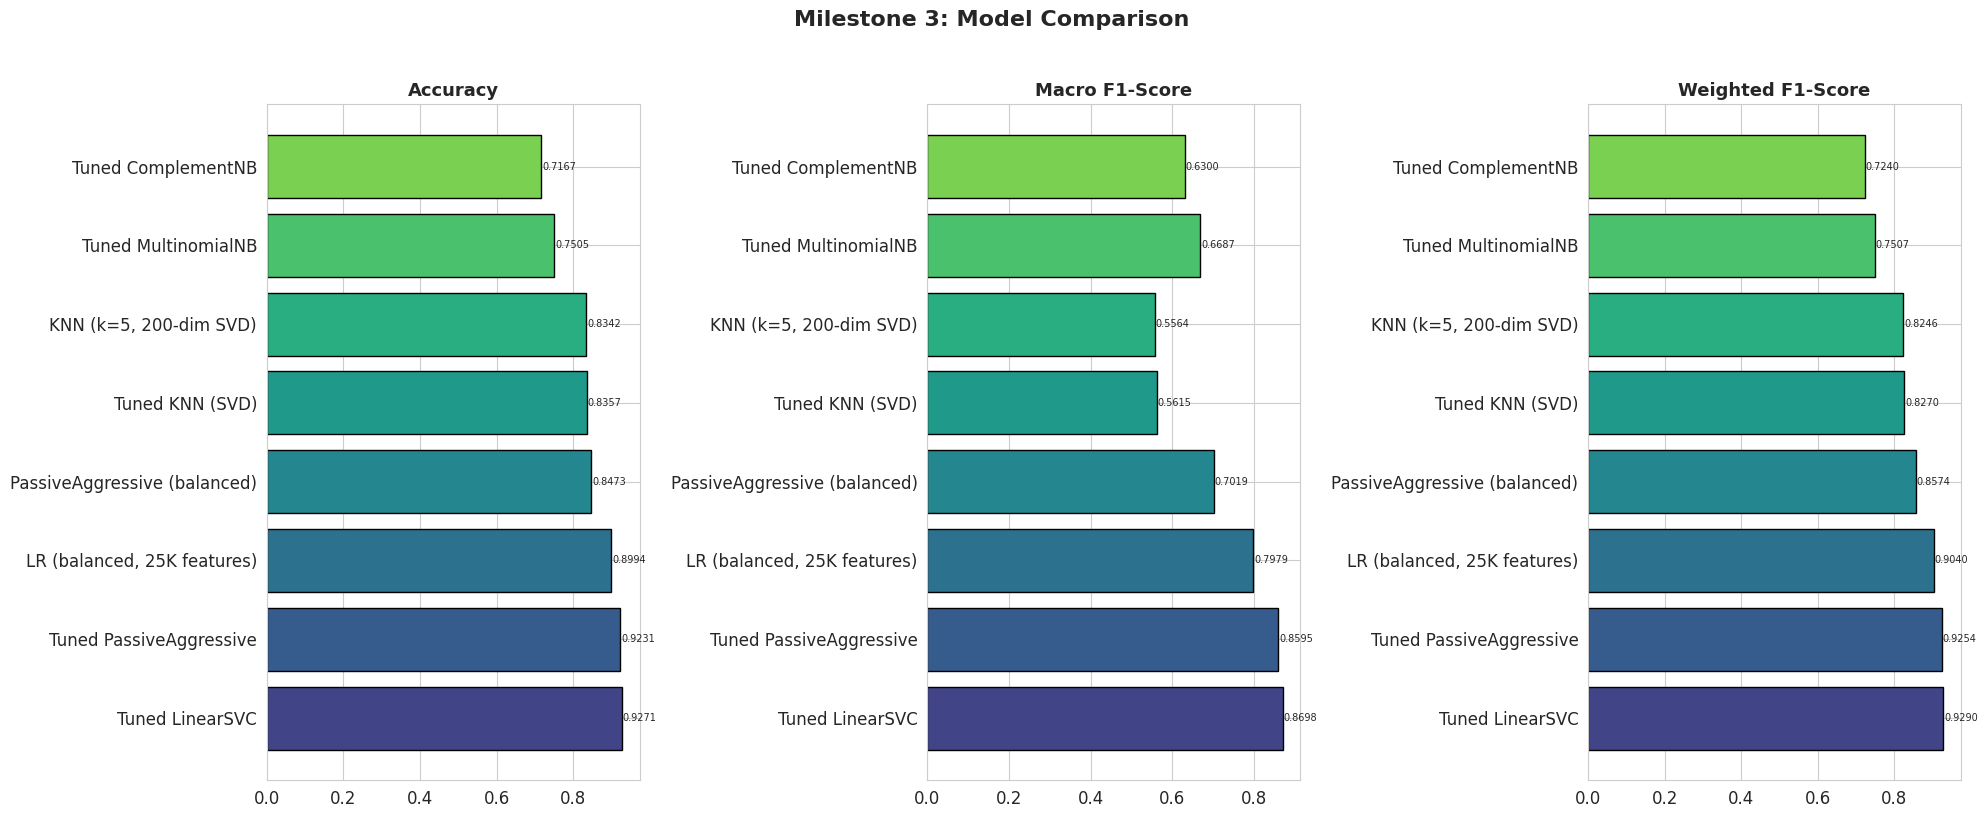

In [33]:
# Visualization
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
metrics = ["accuracy", "macro_f1", "weighted_f1"]
titles  = ["Accuracy", "Macro F1-Score", "Weighted F1-Score"]
colors_bar = plt.cm.viridis(np.linspace(0.2, 0.8, len(results_df)))

for idx, (metric, title) in enumerate(zip(metrics, titles)):
    bars = axes[idx].barh(results_df["name"], results_df[metric],
                          color=colors_bar, edgecolor="black")
    axes[idx].set_title(title, fontsize=13, fontweight="bold")
    for bar, val in zip(bars, results_df[metric]):
        axes[idx].text(val + 0.002, bar.get_y() + bar.get_height()/2,
                      f"{val:.4f}", va="center", fontsize=7)

plt.suptitle("Milestone 3: Model Comparison", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

 ## 15. Confusion Matrices — Top Models

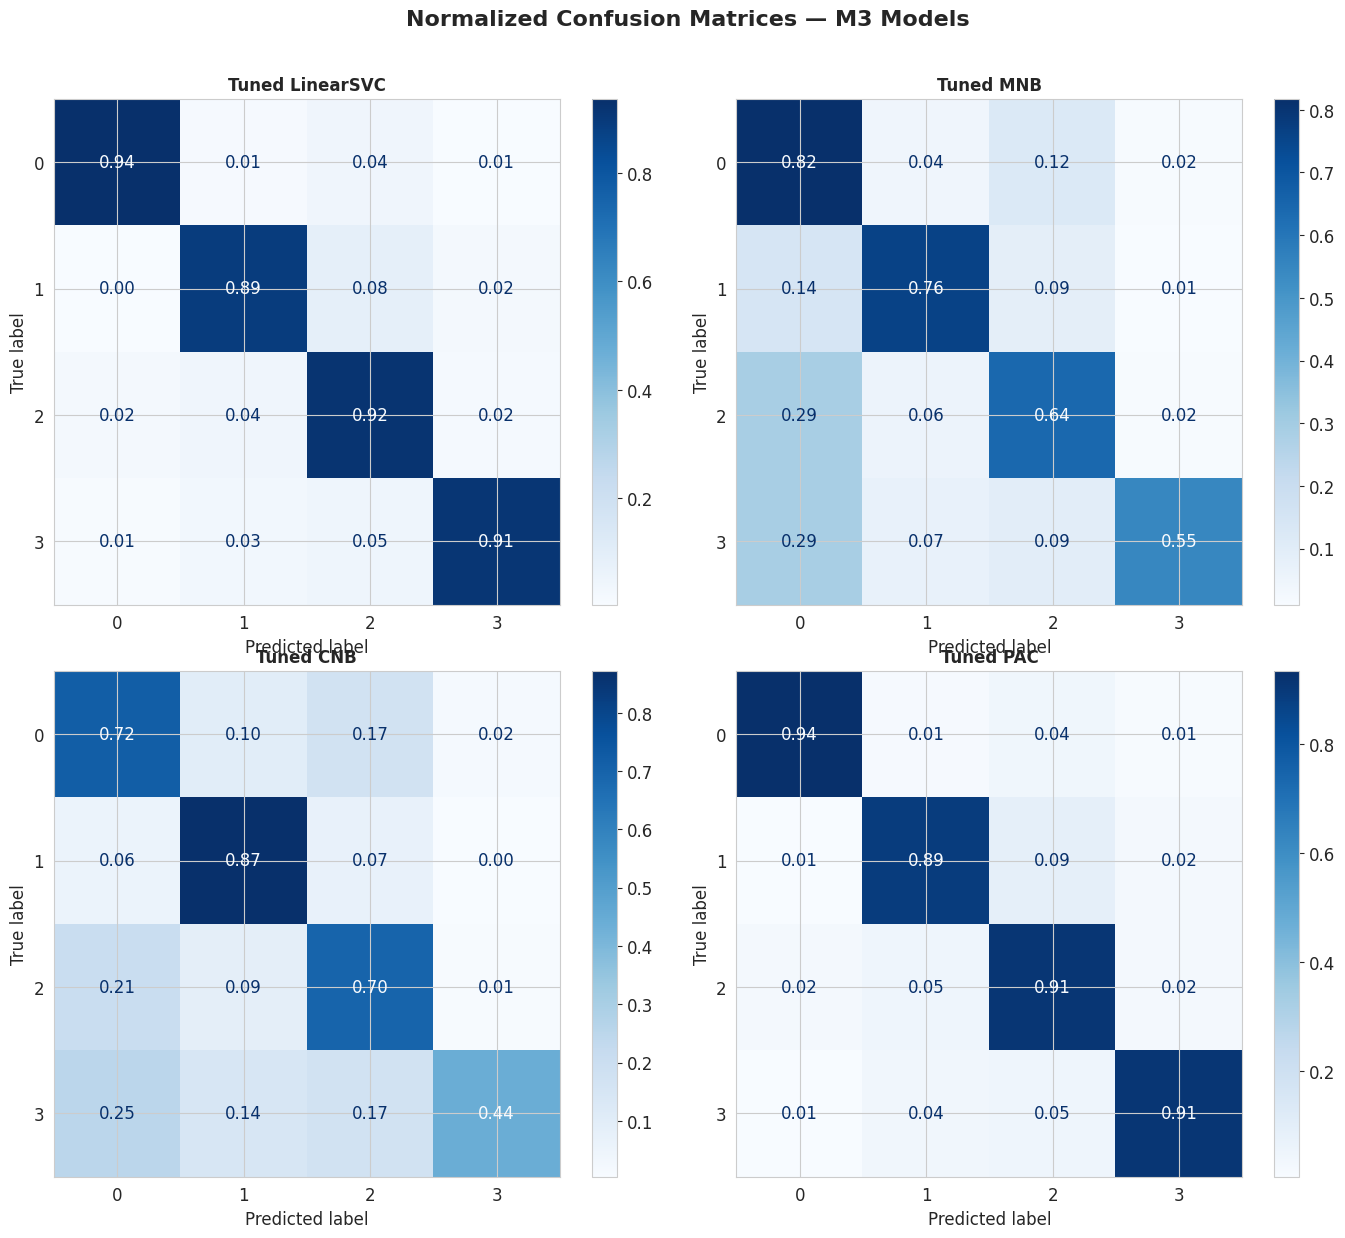

In [34]:
# Get top 4 tuned models
top_models_preds = {}
for name_key, model_obj, data in [
    ("Tuned LinearSVC", grid_lsvc, X_all),
    ("Tuned MNB", grid_mnb, X_all_nonneg_full),
    ("Tuned CNB", grid_cnb, X_all_nonneg_full),
    ("Tuned PAC", grid_pac, X_all),
]:
    top_models_preds[name_key] = model_obj.predict(data[idx_val])

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for idx, (name, preds) in enumerate(top_models_preds.items()):
    ax = axes[idx // 2][idx % 2]
    cm = confusion_matrix(y_vl, preds, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=[0, 1, 2, 3]).plot(
        ax=ax, cmap="Blues", values_format=".2f")
    ax.set_title(name, fontsize=12, fontweight="bold")

plt.suptitle("Normalized Confusion Matrices — M3 Models",
             fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 16. Generate Submission with Best Model

In [35]:
best_idx = results_df["accuracy"].idxmax()
best_name = results_df.loc[best_idx, "name"]
best_acc  = results_df.loc[best_idx, "accuracy"]
print(f"🏆 Best Model: {best_name} (Accuracy: {best_acc:.4f})")


🏆 Best Model: Tuned LinearSVC (Accuracy: 0.9271)


In [36]:
# Map to fitted models (GridSearchCV models already refit on full data)
# NOTE: Each model uses its appropriate test matrix:
#   - LinearSVC/PAC/LR → X_test_all (can handle negative values from StandardScaler)
#   - NB models → X_test_nonneg_full (needs non-negative values, uses MinMaxScaler)
#   - KNN → X_test_svd (needs SVD-reduced dimensions, can't work on 25K features)
submission_models = {
    "Tuned LinearSVC": (grid_lsvc, X_test_all),
    "Tuned MultinomialNB": (grid_mnb, X_test_nonneg_full),
    "Tuned ComplementNB": (grid_cnb, X_test_nonneg_full),
    "Tuned PassiveAggressive": (grid_pac, X_test_all),
    # "Tuned KNN (SVD)": (grid_knn, X_test_svd),  # KNN on SVD-reduced test data
}
# Pick the best by matching name
best_model_obj = None
best_test_data = None

for key, (model, test_data) in submission_models.items():
    if key in best_name or best_name in key:
        best_model_obj = model
        best_test_data = test_data
        print(f"Using: {key}")
        break

if best_model_obj is None:
    # Fallback to LinearSVC (usually best)
    print("Falling back to Tuned LinearSVC")
    best_model_obj = grid_lsvc
    best_test_data = X_test_all


Using: Tuned LinearSVC


In [37]:
test_predictions = best_model_obj.predict(best_test_data)

submission = sample.copy()
submission["label"] = test_predictions

print("📋 Submission preview:")
print(submission.head(10))
print(f"\nPrediction distribution:")
print(pd.Series(test_predictions).value_counts().sort_index())

# %%
submission.to_csv("submission.csv", index=False)
print("✅ Submission saved to 'submission.csv'")

📋 Submission preview:
   ID  label
0   1      2
1   2      2
2   3      0
3   4      0
4   5      2
5   6      0
6   7      1
7   8      0
8   9      0
9  10      2

Prediction distribution:
0    55885
1     9193
2    33346
3     3576
Name: count, dtype: int64
✅ Submission saved to 'submission.csv'


## 17. Bonus: Multiple Submissions (try different models)

In [38]:
# Generate submissions from top models for comparison on Kaggle
for name, (model, test_data) in submission_models.items():
    preds = model.predict(test_data)
    sub = sample.copy()
    sub["label"] = preds
    fname = f"submission_{name.lower().replace(' ', '_').replace('(','').replace(')','')}.csv"
    sub.to_csv(fname, index=False)
    print(f"✅ {fname} saved | Distribution: {dict(zip(*np.unique(preds, return_counts=True)))}")


✅ submission_tuned_linearsvc.csv saved | Distribution: {np.int64(0): np.int64(55885), np.int64(1): np.int64(9193), np.int64(2): np.int64(33346), np.int64(3): np.int64(3576)}
✅ submission_tuned_multinomialnb.csv saved | Distribution: {np.int64(0): np.int64(59659), np.int64(1): np.int64(10400), np.int64(2): np.int64(29138), np.int64(3): np.int64(2803)}
✅ submission_tuned_complementnb.csv saved | Distribution: {np.int64(0): np.int64(50037), np.int64(1): np.int64(15738), np.int64(2): np.int64(33851), np.int64(3): np.int64(2374)}
✅ submission_tuned_passiveaggressive.csv saved | Distribution: {np.int64(0): np.int64(55859), np.int64(1): np.int64(9405), np.int64(2): np.int64(33006), np.int64(3): np.int64(3730)}


 ## 18. Milestone 3 Summary

 ### Models Trained:
 | # | Model | Type | Status |
 |---|-------|------|--------|
| 1 | MultinomialNB | Naive Bayes | ✅ Tuned |
 | 2 | ComplementNB | Naive Bayes (imbalanced) | ✅ Tuned |
 | 3 | LinearSVC | SVM (linear) | ✅ Tuned |
 | 4 | PassiveAggressiveClassifier | Online linear | ✅ Tuned |
 | 5 | Logistic Regression | Linear (from M2) | ✅ with char n-grams |
 | 6 | KNN | Instance-based | ✅ Tuned with TruncatedSVD |
 ### Feature Improvements:
 - Character n-gram TF-IDF (10K features) added
 - TruncatedSVD for dimensionality reduction (KNN)
 - SelectKBest (chi2) for feature selection
 - Tested with and without class_weight="balanced"
